# 📘 GradeBook – Student Result Analyzer and Grading System
### Python Programming Group Project · Group 01 · Domain: Education
**B.Tech CSE (Data Science) · Semester III**

| # | Member | USN | Component |
|---|---|---|---|
| 1 | Amulya | 25BTRDC008 | Menu, input and validation |
| 2 | Adithya Sapkal | 25BTRDC043 | Core logic and functions |
| 3 | Aditiya Sahrawat | 25BTRDC003 | Data structures |
| 4 | Sinchana G | 25BTRDC048 | Files and error handling |
| 5 | Shivani M | 25BTRDC046 | Data analysis |
| 6 | Swarnava Banerjee | 25BTRDC053 | Visualisation and report |

**Problem:** Teachers spend hours computing totals, percentages, grades and SGPA by hand at the end of every semester, and it is hard to see which subjects are weak or which students need support.

**Solution:** GradeBook is a menu-driven Python application that stores marks for a class, calculates totals, percentages, grades and SGPA automatically, ranks students, saves everything to CSV/JSON files, and uses pandas and matplotlib to show subject averages, toppers, pass percentage and grade distribution.

**Contents**
1. Import libraries and project modules
2. Load and explore the dataset
3. Data cleaning
4. Core logic – grades and SGPA
5. Data analysis with pandas
6. Data visualisation with matplotlib
7. Data structures
8. Functions – *args, **kwargs, lambda, recursion
9. Error handling tests
10. Saving and loading files
11. Running the menu-driven program
12. Conclusion

## 1. Import libraries and project modules

In [1]:
import json
import os
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
%matplotlib inline

# Our 6 project components (one .py file per member)
import menu_input as ui
import core_logic
import data_structures as ds
import file_handler
import analysis
import visualisation
import main

print("Libraries and all 6 GradeBook components imported successfully!")

Libraries and all 6 GradeBook components imported successfully!


## 2. Load and explore the dataset
The class marks are stored in **`data/marks.csv`** (one row per student per subject). Course settings are in **`data/settings.json`**.

In [2]:
df = pd.read_csv("data/marks.csv")

print("GradeBook Dataset Loaded Successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
display(df.head(10))

GradeBook Dataset Loaded Successfully!
Total Rows: 600
Total Columns: 4


,usn,name,subject,mark
0,25BTRDS001,Lakshmi Rao,Maths,73.0
1,25BTRDS001,Lakshmi Rao,Python,74.0
2,25BTRDS001,Lakshmi Rao,Physics,49.0
3,25BTRDS001,Lakshmi Rao,English,94.0
4,25BTRDS001,Lakshmi Rao,Electronics,77.0
5,25BTRDS002,Asha Singh,Maths,81.0
6,25BTRDS002,Asha Singh,Python,64.0
7,25BTRDS002,Asha Singh,Physics,NaN
8,25BTRDS002,Asha Singh,English,74.0
9,25BTRDS002,Asha Singh,Electronics,68.0


In [3]:
with open("data/settings.json") as f:
    settings = json.load(f)

credits = settings["subjects"]
pass_mark = settings["pass_mark"]

print("Class:", settings["class_name"])
print("Pass mark:", pass_mark)
print("\nSubjects and credits:")
for subject, credit in credits.items():
    print(f"  {subject:<12} {credit} credits")
print("Total credits:", sum(credits.values()))

Class: B.Tech CSE (Data Science) - Sem III
Pass mark: 40

Subjects and credits:
  Maths        4 credits
  Python       4 credits
  Physics      3 credits
  English      2 credits
  Electronics  3 credits
Total credits: 16


In [4]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Column Names:
['usn', 'name', 'subject', 'mark']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   usn      600 non-null    str    
 1   name     600 non-null    str    
 2   subject  600 non-null    str    
 3   mark     590 non-null    float64
dtypes: float64(1), str(3)
memory usage: 18.9 KB


In [5]:
print("Number of students:", df["usn"].nunique())
print("Number of subjects:", df["subject"].nunique())
print("Subjects:", sorted(df["subject"].unique()))
print("\nStatistical summary of marks:")
display(df["mark"].describe().round(2).to_frame())

Number of students: 120
Number of subjects: 5
Subjects: ['Electronics', 'English', 'Maths', 'Physics', 'Python']

Statistical summary of marks:


,mark
count,590.00
mean,67.67
std,16.75
min,4.00
25%,56.00
50%,68.00
75%,79.00
max,100.00


In [6]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
usn         0
name        0
subject     0
mark       10
dtype: int64

Duplicate Rows: 0


## 3. Data cleaning
Some marks are blank (the student was absent or marks were not entered). We **do not** replace them with 0, because that would unfairly lower the class average. Instead we keep them as missing (`NaN`) and flag those students.

In [7]:
df["mark"] = pd.to_numeric(df["mark"], errors="coerce")
df["usn"] = df["usn"].str.strip().str.upper()
df["name"] = df["name"].str.strip().str.title()

missing_rows = df[df["mark"].isna()]
print("Records with missing marks:", len(missing_rows))
display(missing_rows)

Records with missing marks: 10


,usn,name,subject,mark
7,25BTRDS002,Asha Singh,Physics,NaN
151,25BTRDS031,Kavya Hegde,Python,NaN
163,25BTRDS033,Sneha Patel,English,NaN
234,25BTRDS047,Manoj Menon,Electronics,NaN
252,25BTRDS051,Rahul Joshi,Physics,NaN
366,25BTRDS074,Sneha Patel,Python,NaN
376,25BTRDS076,Deepa Reddy,Python,NaN
427,25BTRDS086,Meera Verma,Physics,NaN
430,25BTRDS087,Kiran Rao,Maths,NaN
472,25BTRDS095,Divya Sharma,Physics,NaN


In [8]:
# Check that every entered mark is in the valid range 0-100
invalid = df[(df["mark"] < 0) | (df["mark"] > 100)]
print("Marks outside 0-100:", len(invalid))
print("Data is clean and ready for analysis!")

Marks outside 0-100: 0
Data is clean and ready for analysis!


In [9]:
# Wide table: one row per student, one column per subject (pivot_table)
wide = df.pivot_table(index=["usn", "name"], columns="subject", values="mark").reset_index()
wide.columns.name = None
print("Marks sheet (first 10 students):")
display(wide.head(10))

Marks sheet (first 10 students):


,usn,name,Electronics,English,Maths,Physics,Python
0,25BTRDS001,Lakshmi Rao,77.0,94.0,73.0,49.0,74.0
1,25BTRDS002,Asha Singh,68.0,74.0,81.0,NaN,64.0
2,25BTRDS003,Shreya Nair,79.0,87.0,61.0,75.0,86.0
3,25BTRDS004,Lakshmi Menon,63.0,54.0,63.0,67.0,84.0
4,25BTRDS005,Tanvi Nair,67.0,93.0,62.0,80.0,95.0
5,25BTRDS006,Gaurav Shetty,79.0,64.0,66.0,68.0,85.0
6,25BTRDS007,Deepa Nair,46.0,83.0,33.0,61.0,66.0
7,25BTRDS008,Rohan Patel,63.0,90.0,76.0,68.0,90.0
8,25BTRDS009,Pooja Singh,75.0,78.0,50.0,81.0,77.0
9,25BTRDS010,Asha Joshi,83.0,79.0,68.0,71.0,93.0


## 4. Core logic – grades and SGPA (`core_logic.py`)

| Marks | Grade | Grade point |
|---|---|---|
| 90–100 | O | 10 |
| 80–89 | A+ | 9 |
| 70–79 | A | 8 |
| 60–69 | B+ | 7 |
| 50–59 | B | 6 |
| 40–49 | C | 5 |
| below 40 | F | 0 |

**SGPA = Σ (credits × grade point) ÷ Σ credits**

In [10]:
for test_mark in [95, 84, 73, 66, 55, 42, 30, None]:
    print(f"Mark {str(test_mark):>4}  ->  Grade, Point = {core_logic.grade(test_mark)}")

Mark   95  ->  Grade, Point = ('O', 10)
Mark   84  ->  Grade, Point = ('A+', 9)
Mark   73  ->  Grade, Point = ('A', 8)
Mark   66  ->  Grade, Point = ('B+', 7)
Mark   55  ->  Grade, Point = ('B', 6)
Mark   42  ->  Grade, Point = ('C', 5)
Mark   30  ->  Grade, Point = ('F', 0)
Mark None  ->  Grade, Point = ('AB', 0)


In [11]:
# Full result of one student, calculated with our functions
marks = {row.subject: (None if pd.isna(row.mark) else int(row.mark))
         for row in df[df["usn"] == "25BTRDS001"].itertuples()}

print("========== RESULT : 25BTRDS001 ==========")
print("Marks      :", marks)
print("Total      :", core_logic.total(marks), "/ 500")
print("Percentage :", core_logic.percentage(marks), "%")
print("SGPA       :", core_logic.sgpa(marks, credits))
print("Result     :", core_logic.result_status(marks, pass_mark))

========== RESULT : 25BTRDS001 ==========
Marks      : {'Maths': 73, 'Python': 74, 'Physics': 49, 'English': 94, 'Electronics': 77}
Total      : 367 / 500
Percentage : 73.4 %
SGPA       : 7.69
Result     : PASS


In [12]:
df = analysis.build_dataframe(df[["usn", "name", "subject", "mark"]].values.tolist(), credits)
print("Grade and grade point added to every record:")
display(df.head(10))

Grade and grade point added to every record:


,usn,name,subject,mark,credits,grade,grade_point
0,25BTRDS001,Lakshmi Rao,Maths,73.0,4,A,8
1,25BTRDS001,Lakshmi Rao,Python,74.0,4,A,8
2,25BTRDS001,Lakshmi Rao,Physics,49.0,3,C,5
3,25BTRDS001,Lakshmi Rao,English,94.0,2,O,10
4,25BTRDS001,Lakshmi Rao,Electronics,77.0,3,A,8
5,25BTRDS002,Asha Singh,Maths,81.0,4,A+,9
6,25BTRDS002,Asha Singh,Python,64.0,4,B+,7
7,25BTRDS002,Asha Singh,Physics,NaN,3,AB,0
8,25BTRDS002,Asha Singh,English,74.0,2,A,8
9,25BTRDS002,Asha Singh,Electronics,68.0,3,B+,7


## 5. Data analysis with pandas (`analysis.py`)

In [13]:
summary = analysis.student_summary(df, pass_mark)
print("Student-wise result summary (ranked by SGPA):")
display(summary[["rank", "usn", "name", "total", "percentage", "sgpa", "result"]].head(10))

Student-wise result summary (ranked by SGPA):


,rank,usn,name,total,percentage,sgpa,result
0,1,25BTRDS065,Suresh Das,484.0,96.8,10.00,PASS
1,2,25BTRDS017,Pooja Das,472.0,94.4,9.56,PASS
2,3,25BTRDS056,Vikram Rao,455.0,91.0,9.38,PASS
3,4,25BTRDS063,Tanvi Das,442.0,88.4,9.19,PASS
4,5,25BTRDS020,Priya Verma,434.0,86.8,9.12,PASS
5,6,25BTRDS053,Shreya Joshi,431.0,86.2,9.00,PASS
6,7,25BTRDS032,Rohan Gupta,418.0,83.6,8.88,PASS
7,8,25BTRDS071,Lakshmi Rao,405.0,81.0,8.88,PASS
8,9,25BTRDS119,Neha Gupta,412.0,82.4,8.81,PASS
9,10,25BTRDS011,Varun Das,413.0,82.6,8.81,PASS


In [14]:
all_marks = df["mark"].dropna().to_numpy()      # NumPy array

print("=" * 45)
print("        GRADEBOOK CLASS RESULT SUMMARY")
print("=" * 45)
print("Total students        :", summary.shape[0])
print("Total records         :", df.shape[0])
print("Class average mark    :", round(np.mean(all_marks), 2))
print("Standard deviation    :", round(np.std(all_marks), 2))
print("Highest mark          :", int(np.max(all_marks)))
print("Lowest mark           :", int(np.min(all_marks)))
print("Average SGPA          :", round(summary["sgpa"].mean(), 2))
print("Pass percentage       :", analysis.pass_percentage(summary), "%")
print("Students passed       :", (summary["result"] == "PASS").sum())
print("Students failed       :", (summary["result"] == "FAIL").sum())
print("Results incomplete    :", (summary["result"] == "INCOMPLETE").sum())
print("=" * 45)

        GRADEBOOK CLASS RESULT SUMMARY
Total students        : 120
Total records         : 600
Class average mark    : 67.67
Standard deviation    : 16.74
Highest mark          : 100
Lowest mark           : 4
Average SGPA          : 6.9
Pass percentage       : 80.9 %
Students passed       : 89
Students failed       : 21
Results incomplete    : 10


In [15]:
subject_stats = df.groupby("subject")["mark"].agg(["mean", "median", "max", "min", "std"]).round(2)
subject_stats["pass_rate_%"] = analysis.subject_pass_rate(df, pass_mark)
subject_stats = subject_stats.sort_values("mean")
print("Subject-wise performance (weakest first):")
display(subject_stats)

Subject-wise performance (weakest first):


,mean,median,max,min,std,pass_rate_%
subject,,,,,,
Physics,59.46,61.0,100.0,4.0,16.10,89.7
Maths,61.99,62.0,92.0,21.0,15.44,91.6
Electronics,65.66,65.0,99.0,29.0,16.12,93.3
Python,73.15,73.0,100.0,36.0,15.32,99.1
English,77.98,78.0,100.0,38.0,13.39,99.2


In [16]:
print("Grade distribution across all subjects:")
display(analysis.grade_distribution(df).to_frame("count"))

Grade distribution across all subjects:


,count
grade,
O,60
A+,85
A,130
B+,137
B,91
C,55
F,32


In [17]:
print("Top 10 students of the class:")
display(analysis.toppers(summary, 10))

Top 10 students of the class:


,rank,usn,name,sgpa,percentage
0,1,25BTRDS065,Suresh Das,10.00,96.8
1,2,25BTRDS017,Pooja Das,9.56,94.4
2,3,25BTRDS056,Vikram Rao,9.38,91.0
3,4,25BTRDS063,Tanvi Das,9.19,88.4
4,5,25BTRDS020,Priya Verma,9.12,86.8
5,6,25BTRDS053,Shreya Joshi,9.00,86.2
6,7,25BTRDS032,Rohan Gupta,8.88,83.6
7,8,25BTRDS071,Lakshmi Rao,8.88,81.0
8,9,25BTRDS119,Neha Gupta,8.81,82.4
9,10,25BTRDS011,Varun Das,8.81,82.6


In [18]:
print("Subject toppers:")
display(analysis.subject_toppers(df).reset_index(drop=True))

Subject toppers:


,subject,usn,name,mark
0,Electronics,25BTRDS076,Deepa Reddy,99.0
1,English,25BTRDS011,Varun Das,100.0
2,Maths,25BTRDS040,Ananya Singh,92.0
3,Physics,25BTRDS017,Pooja Das,100.0
4,Python,25BTRDS017,Pooja Das,100.0


In [19]:
failed = df[(df["mark"] < pass_mark)]
backlogs = failed.groupby(["usn", "name"])["subject"].apply(lambda s: ", ".join(s)).reset_index()
backlogs.columns = ["usn", "name", "failed_subjects"]
print("Students who need support (failed at least one subject):", len(backlogs))
display(backlogs.head(10))

Students who need support (failed at least one subject): 22


,usn,name,failed_subjects
0,25BTRDS007,Deepa Nair,Maths
1,25BTRDS013,Gaurav Singh,"Maths, Physics"
2,25BTRDS030,Ananya Sharma,Electronics
3,25BTRDS033,Sneha Patel,"Physics, Electronics"
4,25BTRDS037,Pooja Sharma,"Physics, Electronics"
5,25BTRDS042,Manoj Shetty,Physics
6,25BTRDS045,Nikhil Shetty,Physics
7,25BTRDS049,Shreya Kumar,Electronics
8,25BTRDS057,Vikram Menon,"Maths, Python, Physics, Electronics"
9,25BTRDS059,Gaurav Patel,Maths


In [20]:
summary["sgpa_band"] = pd.cut(summary["sgpa"], bins=[0, 5, 6, 7, 8, 9, 10],
                              labels=["below 5", "5-6", "6-7", "7-8", "8-9", "9-10"])
print("Number of students in each SGPA band:")
display(summary["sgpa_band"].value_counts().sort_index().to_frame("students"))

Number of students in each SGPA band:


,students
sgpa_band,
below 5,18
5-6,15
6-7,17
7-8,38
8-9,27
9-10,5


In [21]:
print("Correlation between subjects:")
display(wide[sorted(credits)].corr().round(2))

Correlation between subjects:


,Electronics,English,Maths,Physics,Python
Electronics,1.00,0.55,0.67,0.52,0.56
English,0.55,1.00,0.53,0.54,0.62
Maths,0.67,0.53,1.00,0.58,0.55
Physics,0.52,0.54,0.58,1.00,0.56
Python,0.56,0.62,0.55,0.56,1.00


## 6. Data visualisation with matplotlib (`visualisation.py`)
All charts are labelled and saved in the **`charts/`** folder.

In [22]:
paths = visualisation.generate_all(df, pass_mark)


Charts saved:
   charts/1_subject_averages_bar.png
   charts/2_grade_distribution_pie.png
   charts/3_maths_vs_python_scatter.png
   charts/4_dashboard_subplots.png


### Chart 1 – Average marks by subject

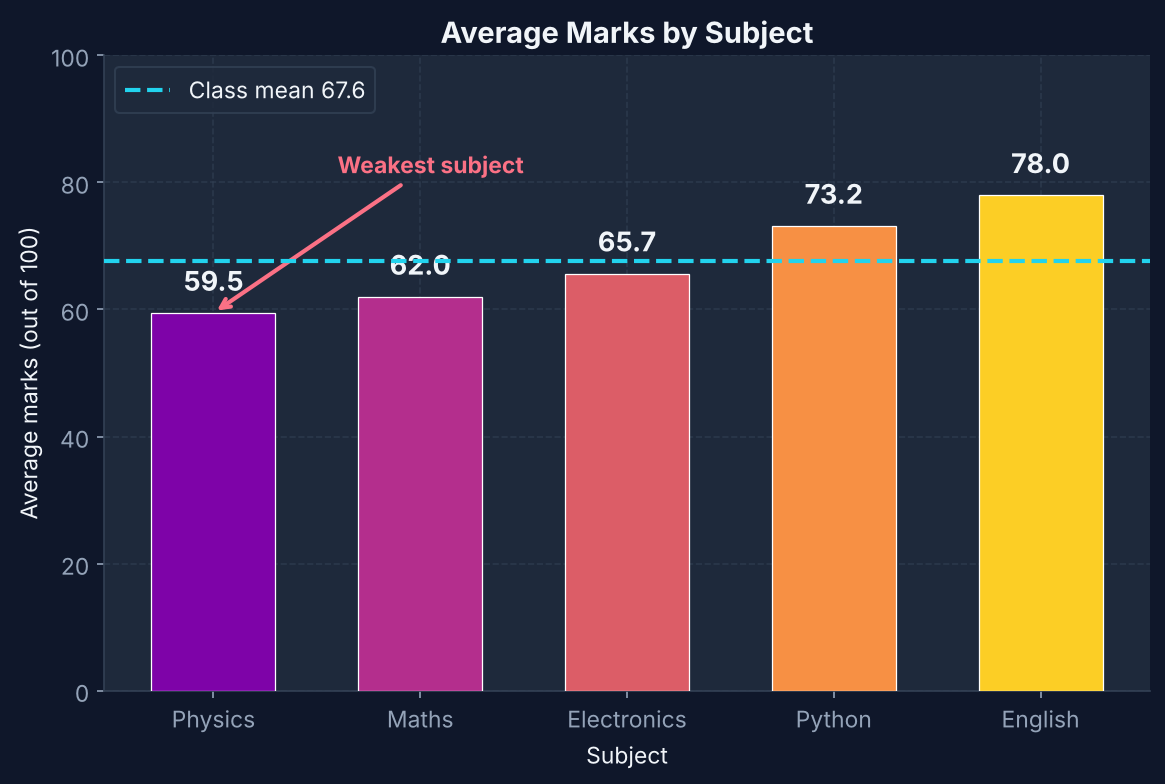

In [23]:
display(Image(filename="charts/1_subject_averages_bar.png"))

### Chart 2 – Grade distribution

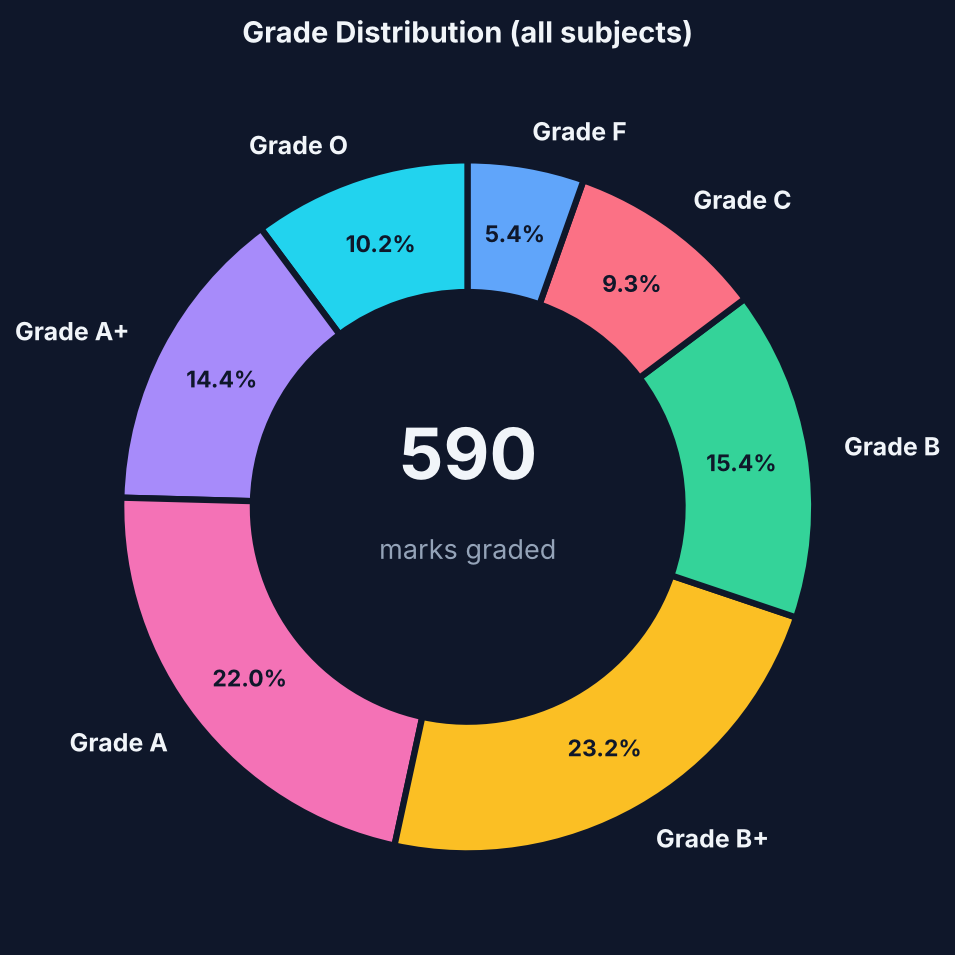

In [24]:
display(Image(filename="charts/2_grade_distribution_pie.png"))

### Chart 3 – Maths vs Python marks

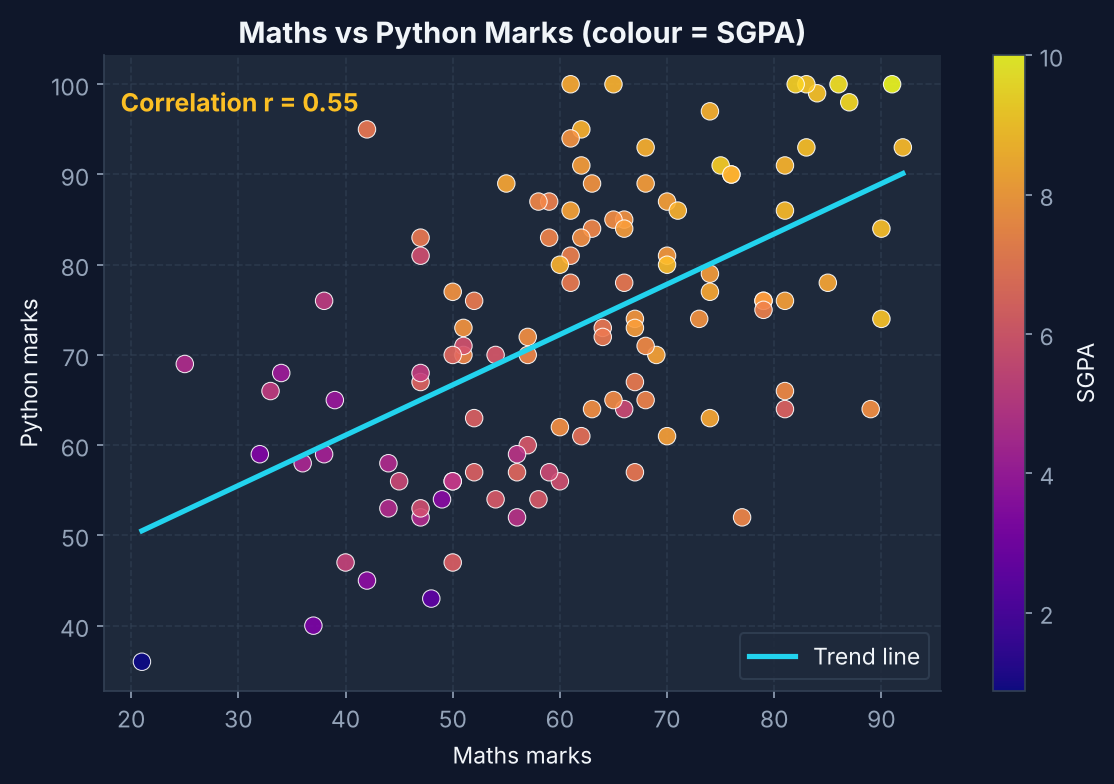

In [25]:
display(Image(filename="charts/3_maths_vs_python_scatter.png"))

### Chart 4 – Class performance dashboard (2 × 2 subplots)

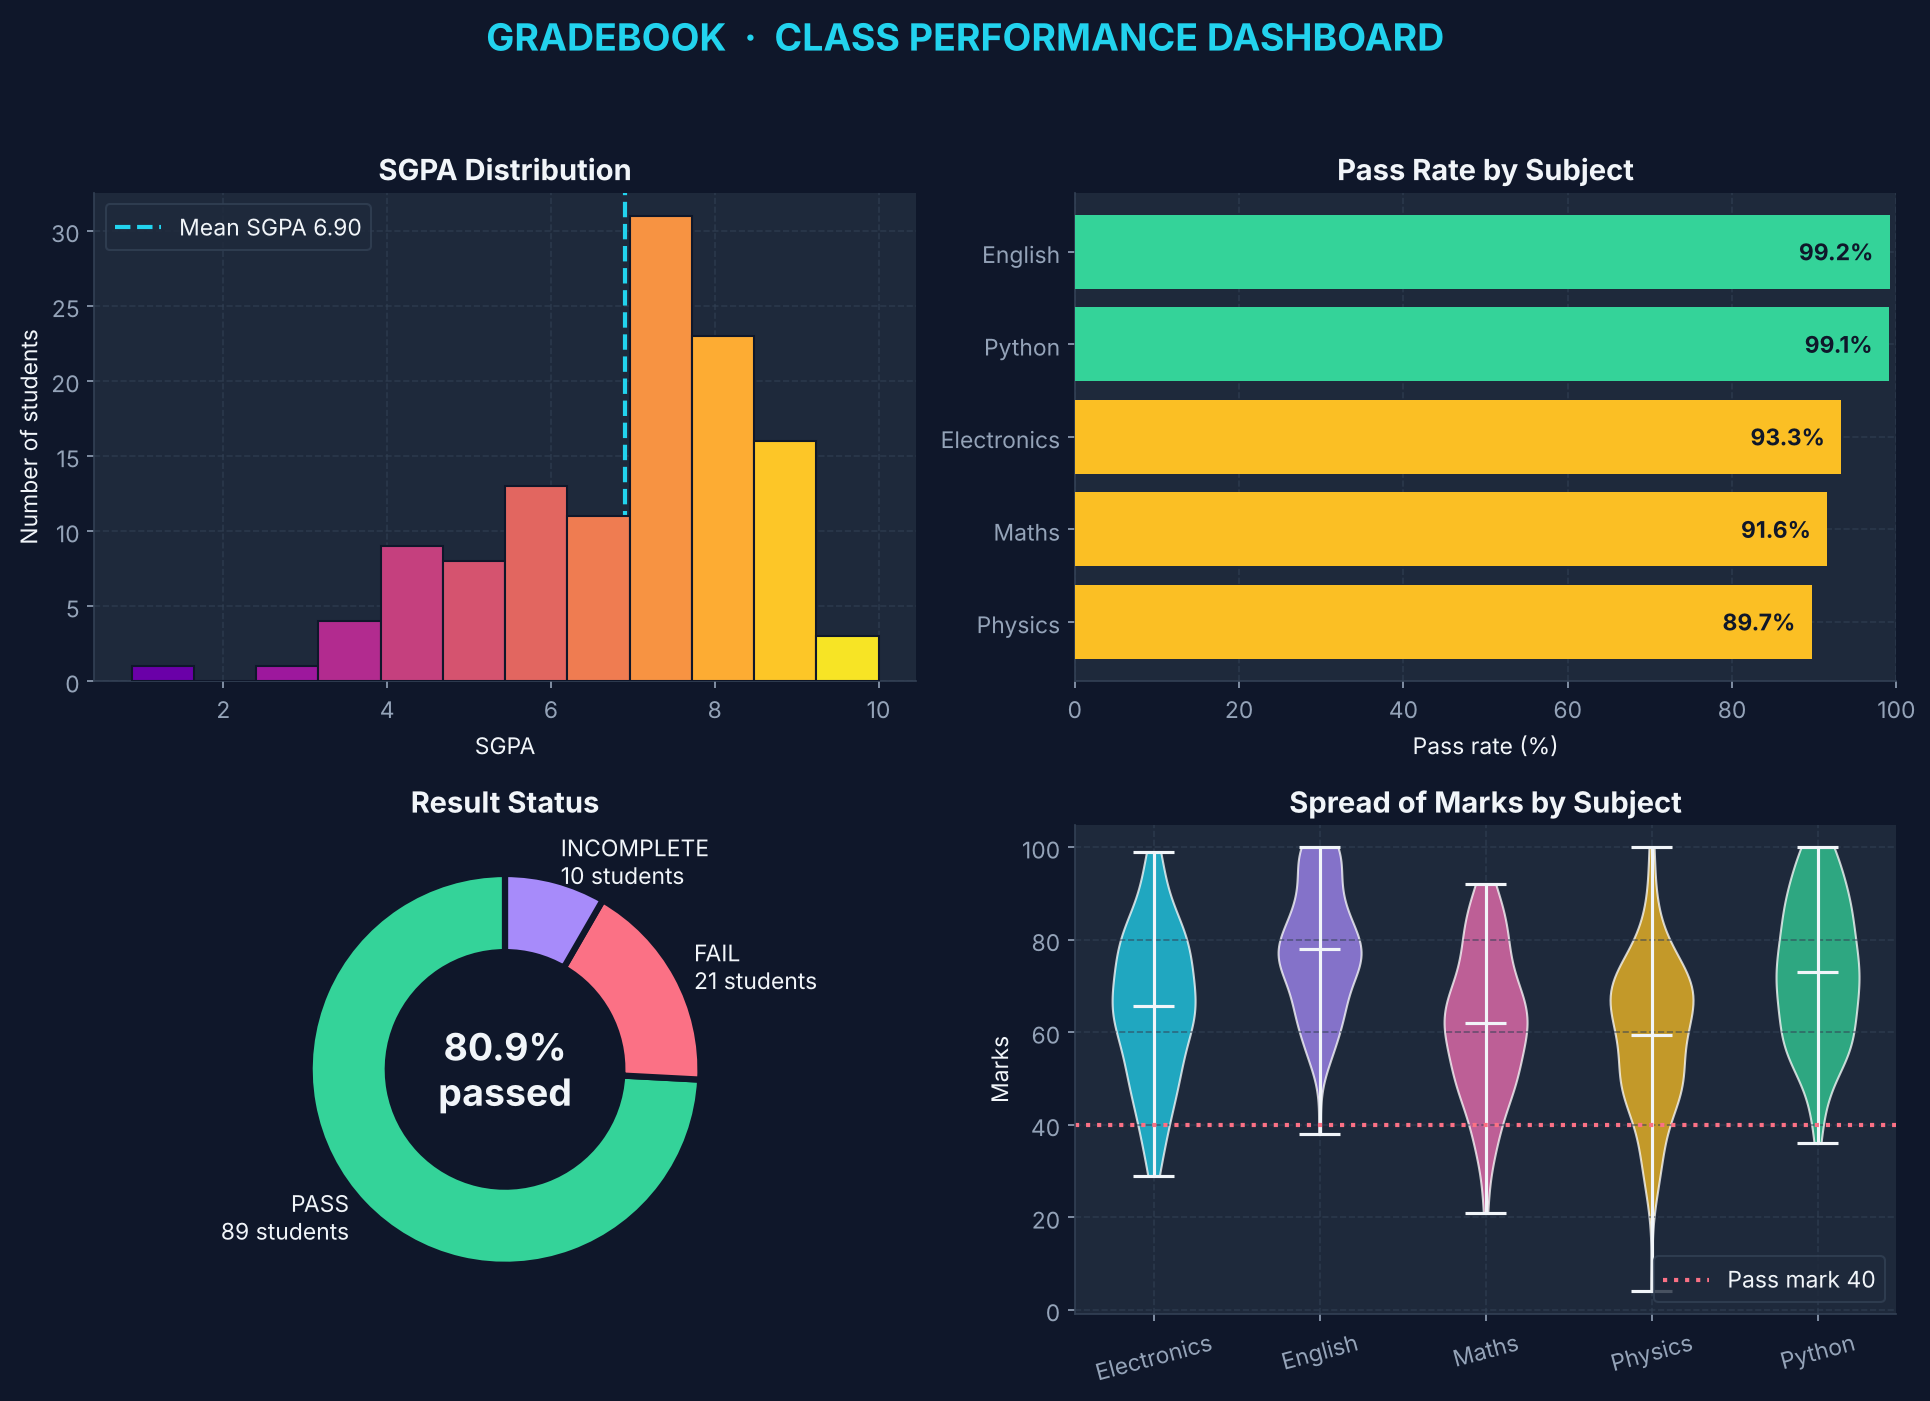

In [26]:
display(Image(filename="charts/4_dashboard_subplots.png"))

### Chart 5 – Subject correlation heatmap

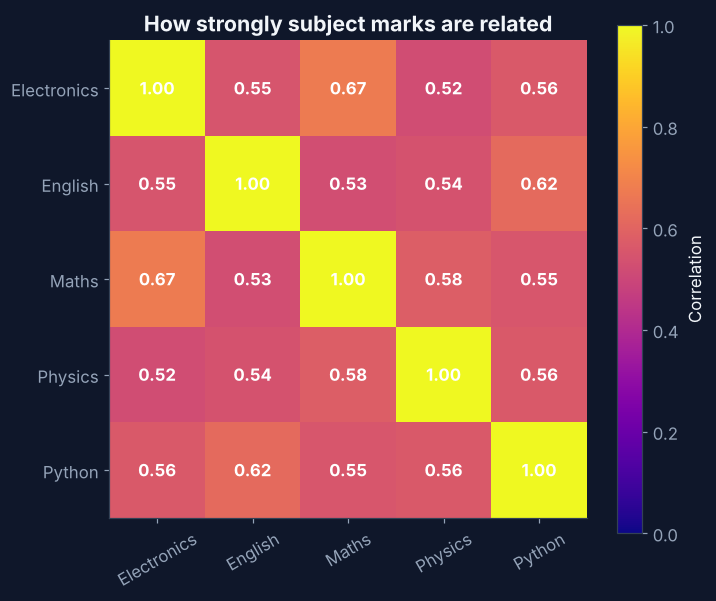

In [27]:
corr = wide[sorted(credits)].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="plasma", vmin=0, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=30)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color="white", fontweight="bold")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("How strongly subject marks are related")
plt.show()

## 7. Data structures (`data_structures.py`)
| Structure | Used for |
|---|---|
| **Dictionary** | USN → student details |
| **Nested dictionary** | subject → mark inside each student |
| **List** | rows saved to the CSV file, ranked results |
| **Tuple** | one `(usn, name, subject, mark)` record |
| **Set** | USNs that still have missing marks |

In [28]:
rows = file_handler.load_marks()               # list of tuples
students = ds.from_rows(rows)                  # nested dictionary

print("Type of rows    :", type(rows).__name__, "of", type(rows[0]).__name__)
print("Type of students:", type(students).__name__)
print("\nOne record (tuple):", rows[0])
print("\nOne student (nested dictionary):")
print(json.dumps({"25BTRDS001": students["25BTRDS001"]}, indent=4))

Type of rows    : list of tuple
Type of students: dict

One record (tuple): ('25BTRDS001', 'Lakshmi Rao', 'Maths', 73)

One student (nested dictionary):
{
    "25BTRDS001": {
        "name": "Lakshmi Rao",
        "marks": {
            "Maths": 73,
            "Python": 74,
            "Physics": 49,
            "English": 94,
            "Electronics": 77
        }
    }
}


In [29]:
missing_set = ds.missing_marks(students)                      # set comprehension
print("Students with missing marks (set):", missing_set)

python_marks = [info["marks"]["Python"] for info in students.values()
                if info["marks"]["Python"] is not None]       # list comprehension
print("\nPython marks of first 10 students (list):", python_marks[:10])

name_lookup = {usn: info["name"] for usn, info in students.items()}   # dict comprehension
print("\nUSN -> name (first 3):", dict(list(name_lookup.items())[:3]))

Students with missing marks (set): {'25BTRDS051', '25BTRDS031', '25BTRDS047', '25BTRDS002', '25BTRDS033', '25BTRDS086', '25BTRDS095', '25BTRDS076', '25BTRDS074', '25BTRDS087'}

Python marks of first 10 students (list): [74, 64, 86, 84, 95, 85, 66, 90, 77, 93]

USN -> name (first 3): {'25BTRDS001': 'Lakshmi Rao', '25BTRDS002': 'Asha Singh', '25BTRDS003': 'Shreya Nair'}


In [30]:
print("Search by name 'priya':")
for usn in ds.search(students, "priya"):
    print(" ", usn, "-", students[usn]["name"])

print("\nSearch by USN '25btrds010':", ds.search(students, "25btrds010"))

Search by name 'priya':
  25BTRDS012 - Priya Rao
  25BTRDS020 - Priya Verma
  25BTRDS092 - Priya Verma
  25BTRDS100 - Priya Verma
  25BTRDS103 - Priya Iyer

Search by USN '25btrds010': ['25BTRDS010']


## 8. Functions – `*args`, `**kwargs`, lambda and recursion

In [31]:
# *args: average of any number of SGPA values
print("Average of 3 SGPAs:", core_logic.class_average(8.2, 7.5, 9.1))

# **kwargs: build a formatted report line
print(core_logic.report_line(USN="25BTRDS001", SGPA=7.69, Result="PASS"))

# lambda: rank students by SGPA
ranked = core_logic.rank_students(students, credits)
print("\nTop 3 using sort(key=lambda row: row[2]):", ranked[:3])

# recursion: count failed subjects
print("\nBacklogs in [35, 72, 20, 90] (recursive):", core_logic.count_backlogs([35, 72, 20, 90]))

Average of 3 SGPAs: 8.27
USN: 25BTRDS001 | SGPA: 7.69 | Result: PASS

Top 3 using sort(key=lambda row: row[2]): [(1, '25BTRDS065', 'Suresh Das', 10.0), (2, '25BTRDS017', 'Pooja Das', 9.56), (3, '25BTRDS056', 'Vikram Rao', 9.38)]

Backlogs in [35, 72, 20, 90] (recursive): 2


## 9. Error handling tests (`menu_input.py`, `file_handler.py`)
To test input without typing, `simulate()` feeds scripted answers to `input()`.

In [32]:
import builtins
real_input = builtins.input

def simulate(answers):
    """Replace input() with scripted answers and print them like a user typing."""
    it = iter(answers)
    def fake_input(prompt=""):
        value = next(it)
        print(prompt + value)
        return value
    builtins.input = fake_input

print("========== TEST 1: marks entered as text / out of range ==========")
simulate(["abc", "150", "-5", "88"])
print("Accepted mark:", ui.get_mark("Maths"))

print("\n========== TEST 2: invalid USN ==========")
simulate(["ab#1", "12", "25BTRDS001"])
print("Accepted USN:", ui.get_usn())

print("\n========== TEST 3: invalid menu choice ==========")
simulate(["15", "x", "4"])
print("Accepted choice:", ui.get_choice())
builtins.input = real_input

========== TEST 1: marks entered as text / out of range ==========
  Marks in Maths (0-100): abc
  Error: please enter a whole number.
  Marks in Maths (0-100): 150
  Error: marks must be between 0 and 100.
  Marks in Maths (0-100): -5
  Error: marks must be between 0 and 100.
  Marks in Maths (0-100): 88
Accepted mark: 88

========== TEST 2: invalid USN ==========
Enter USN: ab#1
  Invalid USN. Use 5-12 letters/digits, e.g. 25BTRDS001.
Enter USN: 12
  Invalid USN. Use 5-12 letters/digits, e.g. 25BTRDS001.
Enter USN: 25BTRDS001
Accepted USN: 25BTRDS001

========== TEST 3: invalid menu choice ==========
Enter your choice: 15
  Invalid choice. Please enter a number from the menu.
Enter your choice: x
  Invalid choice. Please enter a number from the menu.
Enter your choice: 4
Accepted choice: 4


In [33]:
print("========== TEST 4: unknown USN (KeyError) ==========")
try:
    ds.delete_student(students, "XYZ99999")
except KeyError as e:
    print("Handled KeyError ->", e.args[0])

print("\n========== TEST 5: duplicate student (KeyError) ==========")
try:
    ds.add_student(students, "25BTRDS001", "Test Name", credits)
except KeyError as e:
    print("Handled KeyError ->", e.args[0])

========== TEST 4: unknown USN (KeyError) ==========
Handled KeyError -> No student with USN XYZ99999.

========== TEST 5: duplicate student (KeyError) ==========
Handled KeyError -> Student 25BTRDS001 already exists.


In [34]:
print("========== TEST 6: marks file missing (FileNotFoundError) ==========")
original = file_handler.MARKS_FILE
file_handler.MARKS_FILE = "data/does_not_exist.csv"
print("Rows loaded:", len(file_handler.load_marks()))
file_handler.MARKS_FILE = original

print("\n========== TEST 7: damaged settings file (JSONDecodeError) ==========")
with open("data/broken.json", "w") as f:
    f.write("{ this is not valid json")
original = file_handler.SETTINGS_FILE
file_handler.SETTINGS_FILE = "data/broken.json"
print("Settings used:", file_handler.load_settings()["class_name"])
file_handler.SETTINGS_FILE = original
os.remove("data/broken.json")
print("\nThe program never crashed - every error was handled.")

========== TEST 6: marks file missing (FileNotFoundError) ==========
  marks.csv not found - starting with an empty class.
Rows loaded: 0

========== TEST 7: damaged settings file (JSONDecodeError) ==========
  settings.json is damaged - using default settings.
Settings used: B.Tech CSE (Data Science) - Sem III

The program never crashed - every error was handled.


## 10. Saving and loading files

In [35]:
file_handler.save_marks(ds.to_rows(students))

reloaded = pd.read_csv("data/marks.csv")
print("Records in file after saving:", len(reloaded))
print("File last saved:", datetime.fromtimestamp(os.path.getmtime("data/marks.csv")).strftime("%d-%m-%Y %H:%M"))
display(reloaded.tail())

  Saved 600 records to data/marks.csv at 20-11-2026 22:12.
Records in file after saving: 600
File last saved: 20-11-2026 22:12


,usn,name,subject,mark
595,25BTRDS120,Kavya Nair,Maths,64.0
596,25BTRDS120,Kavya Nair,Python,72.0
597,25BTRDS120,Kavya Nair,Physics,44.0
598,25BTRDS120,Kavya Nair,English,76.0
599,25BTRDS120,Kavya Nair,Electronics,69.0


## 11. Running the menu-driven program (`main.py`)
In a terminal: `python main.py`. Here the menu runs with scripted keystrokes.

### Demo 1 – view a student, view ranked class, search

In [36]:
simulate(["3", "25BTRDS001", "4", "5", "rao", "0"])
main.main()
builtins.input = real_input


Loaded 120 students for B.Tech CSE (Data Science) - Sem III.

        GRADEBOOK - Student Result Analyzer
 1. Add a new student
 2. Enter / update marks
 3. View result of a student
 4. View class results (ranked)
 5. Search student by USN or name
 6. Delete a student
 7. Show class analysis (pandas)
 8. Generate charts (matplotlib)
 9. Save data to file
 0. Save and exit
Enter your choice: 3
Enter USN: 25BTRDS001

USN: 25BTRDS001    Name: Lakshmi Rao
Subject        Marks  Grade
Maths             73      A
Python            74      A
Physics           49      C
English           94      O
Electronics       77      A
Total: 367 | Percentage: 73.4% | SGPA: 7.69 | Result: PASS | Backlogs: 0

        GRADEBOOK - Student Result Analyzer
 1. Add a new student
 2. Enter / update marks
 3. View result of a student
 4. View class results (ranked)
 5. Search student by USN or name
 6. Delete a student
 7. Show class analysis (pandas)
 8. Generate charts (matplotlib)
 9. Save data to file
 0. Sa

### Demo 2 – add a new student, enter marks (with a wrong value), view result, then delete

In [37]:
simulate(["1", "25BTRDS999", "Demo Student",
          "2", "25BTRDS999", "ninety", "91", "88", "79", "85", "93",
          "6", "25BTRDS999", "y", "0"])
main.main()
builtins.input = real_input


Loaded 120 students for B.Tech CSE (Data Science) - Sem III.

        GRADEBOOK - Student Result Analyzer
 1. Add a new student
 2. Enter / update marks
 3. View result of a student
 4. View class results (ranked)
 5. Search student by USN or name
 6. Delete a student
 7. Show class analysis (pandas)
 8. Generate charts (matplotlib)
 9. Save data to file
 0. Save and exit
Enter your choice: 1
Enter USN: 25BTRDS999
Enter student name: Demo Student
  Student Demo Student added. Use option 2 to enter marks.

        GRADEBOOK - Student Result Analyzer
 1. Add a new student
 2. Enter / update marks
 3. View result of a student
 4. View class results (ranked)
 5. Search student by USN or name
 6. Delete a student
 7. Show class analysis (pandas)
 8. Generate charts (matplotlib)
 9. Save data to file
 0. Save and exit
Enter your choice: 2
Enter USN: 25BTRDS999
  Marks in Maths (0-100): ninety
  Error: please enter a whole number.
  Marks in Maths (0-100): 91
  Marks in Python (0-100): 88
  

### Demo 3 – class analysis from the menu

In [38]:
simulate(["7", "0"])
main.main()
builtins.input = real_input


Loaded 120 students for B.Tech CSE (Data Science) - Sem III.

        GRADEBOOK - Student Result Analyzer
 1. Add a new student
 2. Enter / update marks
 3. View result of a student
 4. View class results (ranked)
 5. Search student by USN or name
 6. Delete a student
 7. Show class analysis (pandas)
 8. Generate charts (matplotlib)
 9. Save data to file
 0. Save and exit
Enter your choice: 7

----------- CLASS ANALYSIS -----------
Students: 120   Records: 600
Class mean mark: 67.67   Std dev: 16.74
Average SGPA: 6.90
Pass percentage: 80.9%

Subject averages (lowest first):
subject
Physics        59.46
Maths          61.99
Electronics    65.66
Python         73.15
English        77.98

Pass rate by subject (%):
subject
Electronics    93.3
English        99.2
Maths          91.6
Physics        89.7
Python         99.1

Top 5 students:
 rank        usn        name  sgpa  percentage
    1 25BTRDS065  Suresh Das 10.00        96.8
    2 25BTRDS017   Pooja Das  9.56        94.4
    3 25BTRD

## 12. Conclusion
- GradeBook calculates totals, percentages, grades and SGPA for **120 students (600 records)** automatically.
- **Physics (59.5) and Maths (62.0)** are the weakest subjects; faculty can plan extra classes for them.
- **80.9%** of students with complete marks passed every subject; the class average SGPA is **6.90**.
- **10 students** have missing marks and are flagged so their results are not wrongly declared.
- The program handles every wrong input and file problem without crashing, and saves all data to CSV/JSON.

**Future scope:** login for teachers, export report cards as PDF, and email results to students.